In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler , LabelEncoder
from sklearn.impute import SimpleImputer

In [ ]:
#load dataset
df=pd.read_csv('/content/batman_films.csv')
print('Dataset loaded successfull')

In [ ]:
df.shape

(19, 14)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19 entries, 0 to 18
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Year               19 non-null     int64  
 1   Title              19 non-null     object 
 2   Rated              19 non-null     object 
 3   Director           19 non-null     object 
 4   Released           19 non-null     object 
 5   Writer             19 non-null     object 
 6   Production         19 non-null     object 
 7   Actors             19 non-null     object 
 8   Runtime            19 non-null     object 
 9   Awards             19 non-null     object 
 10  Imdb Votes         19 non-null     object 
 11  Imdb Rating        19 non-null     float64
 12  RottenTomatoScore  18 non-null     object 
 13  Metascore          9 non-null      float64
dtypes: float64(2), int64(1), object(11)
memory usage: 2.2+ KB


In [ ]:
df.describe()

,Year,Imdb Rating,Metascore
count,19.000000,19.000000,19.000000
mean,2006.105263,7.226316,59.666667
std,9.579461,1.221948,12.315302
min,1989.000000,3.700000,28.000000
25%,1997.500000,6.600000,59.666667
50%,2010.000000,7.500000,59.666667
75%,2013.500000,8.000000,63.833333
max,2018.000000,9.000000,84.000000


In [ ]:
df.isnull().sum()

,0
Year,0
Title,0
Rated,0
Director,0
Released,0
Writer,0
Production,0
Actors,0
Runtime,0
Awards,0


In [ ]:
#Handling Duplicates
print("No.of Duplicate rows : " , df.duplicated().sum())

No.of Duplicate rows :  0


In [ ]:
#Hamdling Missing Values
df['Metascore'].fillna(df['Metascore'].mean() , inplace = True)
df['RottenTomatoScore'].fillna(df['RottenTomatoScore'].mode()[0] , inplace = True)

/tmp/ipykernel_990/1947571165.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Metascore'].fillna(df['Metascore'].mean() , inplace = True)
/tmp/ipykernel_990/1947571165.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace

In [ ]:
df.drop('Awards', axis=1, inplace=True, errors='ignore')

In [ ]:
df.isnull().sum()

,0
Year,0
Title,0
Rated,0
Director,0
Released,0
Writer,0
Production,0
Actors,0
Runtime,0
Imdb Votes,0


In [ ]:
#create label encoder
le = LabelEncoder()
df['Writer'] = le.fit_transform(df['Writer'])
print(df['Writer'].head())

0     2
1     1
2     5
3    10
4     0
Name: Writer, dtype: int64


In [ ]:
#create MinMaxScaler
scaler = MinMaxScaler()
#Normalize Year Column
df[['Year']] = scaler.fit_transform(df[['Year']])
print(df[['Year']].head())

       Year
0  0.000000
1  0.103448
2  0.137931
3  0.206897
4  0.275862


In [ ]:
# Create a new feature 'CombinedScore' by summing 'Imdb Rating' and 'Metascore' and adding 1
df['CombinedScore'] = df['Imdb Rating'] + df['Metascore'] + 1

print('CombinedScore feature created')
display(df[['Imdb Rating', 'Metascore', 'CombinedScore']].head())

CombinedScore feature created


,Imdb Rating,Metascore,CombinedScore
0,7.5,69.0,77.5
1,7.0,68.0,76.0
2,7.8,68.0,76.8
3,5.4,51.0,57.4
4,3.7,28.0,32.7


In [ ]:
# Create new feature 'IsScoreOne' where 1 indicates CombinedScore is exactly 1
df['IsScoreOne'] = df['CombinedScore'].apply(lambda x : 1 if x == 1 else 0)
print('IsScoreOne feature created')
display(df[['CombinedScore' , 'IsScoreOne']].head())

IsScoreOne feature created


,CombinedScore,IsScoreOne
0,77.5,0
1,76.0,0
2,76.8,0
3,57.4,0
4,32.7,0


In [ ]:
# Add 'MovieTeamScore' and 'IsSoloTeam' features to the dataset, adapted from 'FamilySize' and 'IsAlone'
df['MovieTeamScore'] = df['Imdb Rating'] + df['Metascore'] + 1
df['IsSoloTeam'] = df['MovieTeamScore'].apply(lambda x : 1 if x == 1 else 0)
print('MovieTeamScore and IsSoloTeam features added to the dataset')

MovieTeamScore and IsSoloTeam features added to the dataset


In [ ]:
# Outlier detection for 'Imdb Rating' using IQR method
Q1_imdb = df['Imdb Rating'].quantile(0.25)
Q3_imdb = df['Imdb Rating'].quantile(0.75)
IQR_imdb = Q3_imdb - Q1_imdb
lower_limit = Q1_imdb - 1.5 * IQR_imdb
upper_limit = Q3_imdb + 1.5 * IQR_imdb
outliers_imdb = (df['Imdb Rating'] < lower_limit) | (df['Imdb Rating'] > upper_limit)
print("Outliers removed")



Outliers removed


In [ ]:
print("Dataset shape After removing outliers : " , df.shape)

Dataset shape After removing outliers :  (19, 17)


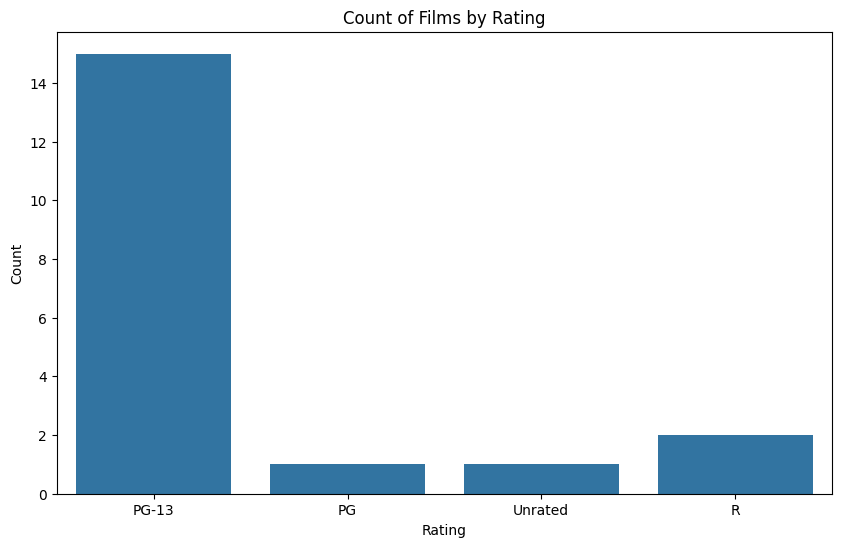

In [ ]:
plt.figure(figsize = (10 , 6))
sns.countplot(x = 'Rated' , data = df)
plt.title('Count of Films by Rating')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.show()

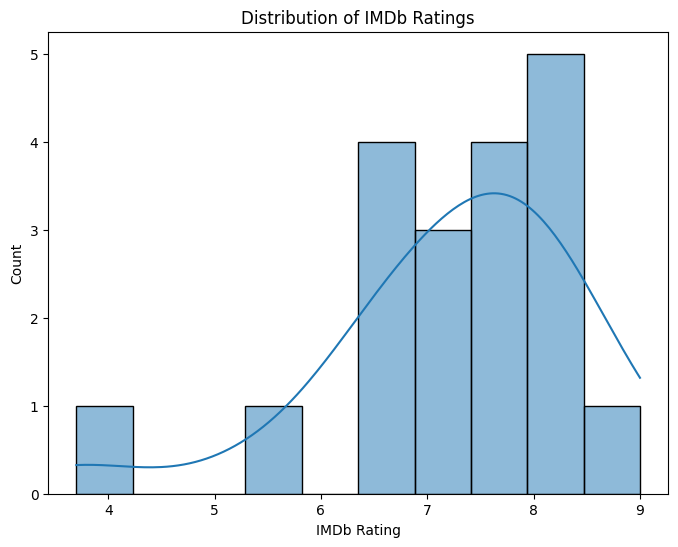

In [ ]:
#plot the distribution of the Imdb Ratings
plt.figure(figsize = (8 , 6))
sns.histplot( df['Imdb Rating'] , bins= 10, kde = True)
plt.title('Distribution of IMDb Ratings')
plt.xlabel('IMDb Rating')
plt.ylabel('Count')
plt.show()

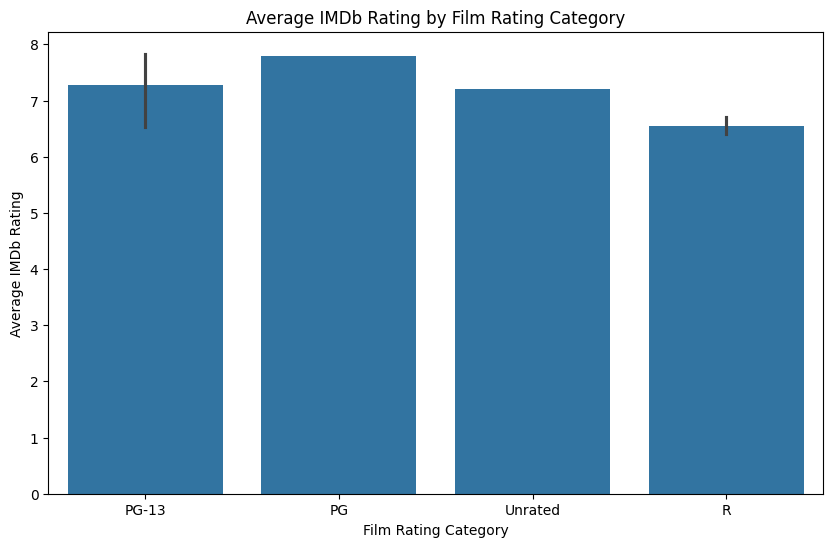

In [ ]:
#Bivariate Visualizations bar chart OS avg imdb by film rating
plt.figure(figsize = (10 , 6))
sns.barplot(x = 'Rated' , y = 'Imdb Rating' , data = df)
plt.title('Average IMDb Rating by Film Rating Category')
plt.xlabel('Film Rating Category')
plt.ylabel('Average IMDb Rating')
plt.show()

In [ ]:
drop_columns = ['Production']
df.drop(drop_columns, axis=1, inplace=True, errors='ignore')
print('Columns dropped successfully')

Columns dropped successfully


In [ ]:
#Displays side-by-side comparison of raw vs processed dataset(first 10  rows)
#After data comparison
print("After preprocessing")
display(df.head(10))

After preprocessing


,Year,Rated,Director,Released,Writer,Runtime,Imdb Votes,Imdb Rating,RottenTomatoScore,Metascore,CombinedScore,IsScoreOne,MovieTeamScore,IsSoloTeam
0,0.000000,PG-13,Tim Burton,6/23/1989,2,126 min,"323,942",7.5,72.0,69.0,77.5,0,77.5,0
1,0.103448,PG-13,Tim Burton,6/19/1992,1,126 min,"261,654",7.0,79.0,68.0,76.0,0,76.0,0
2,0.137931,PG,"Eric Radomski, Bruce Timm, Kevin Altieri, Boyd...",12/25/1993,5,76 min,"40,226",7.8,84.0,68.0,76.8,0,76.8,0
3,0.206897,PG-13,Joel Schumacher,6/16/1995,10,121 min,"226,680",5.4,39.0,51.0,57.4,0,57.4,0
4,0.275862,PG-13,Joel Schumacher,6/20/1997,0,125 min,"224,614",3.7,11.0,28.0,32.7,0,32.7,0
5,0.310345,Unrated,Boyd Kirkland,3/17/1998,3,70 min,"12,490",7.2,92.0,68.0,76.2,0,76.2,0
6,0.379310,PG-13,Curt Geda,12/12/2000,8,76 min,"22,149",7.8,90.0,68.0,76.8,0,76.8,0
7,0.551724,PG-13,Christopher Nolan,6/15/2005,9,140 min,"1,241,089",8.2,84.0,70.0,79.2,0,79.2,0
8,0.655172,PG-13,Christopher Nolan,7/18/2008,16,152 min,"2,173,344",9.0,94.0,84.0,94.0,0,94.0,0
9,0.724138,PG-13,Brandon Vietti,7/27/2010,17,75 min,"51,426",8.0,100.0,68.0,77.0,0,77.0,0
